# Kesit İstatistik — İleri zaman serileri

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## ACF, PACF ve artık beyaz gürültüsü

Tahmin artıklarında zaman bağımlılığı kaldı mı?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** AR(1) serisinin ACF ve PACF desenini incele.

**Yorum sınırı:** Gecikme bantları yaklaşık ve çoklu bakış içerir; beyaz gürültü testi model doğruluğunu kanıtlamaz.

**Alıştırma:** AR katsayısını .7’den 0’a değiştir; Ljung–Box ve grafiği birlikte oku.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


       lb_stat     lb_pvalue
8   325.696185  1.384184e-65
16  329.306600  2.110034e-60


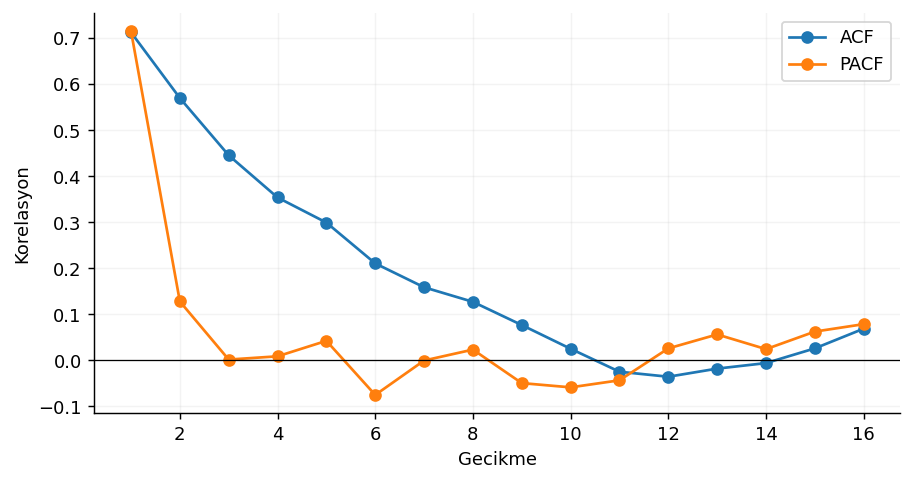

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from statsmodels.tsa.stattools import acf,pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
x=np.zeros(240)
for t in range(1,len(x)):x[t]=.7*x[t-1]+rng.normal()
a=acf(x,nlags=16);p=pacf(x,nlags=16);print(acorr_ljungbox(x,lags=[8,16],return_df=True));plt.plot(range(1,17),a[1:],'o-',label='ACF');plt.plot(range(1,17),p[1:],'o-',label='PACF');plt.axhline(0,c='black',lw=.7);plt.xlabel('Gecikme');plt.ylabel('Korelasyon');plt.legend()

## Değişim noktaları ve yapısal kırılmalar

Süreçte kalıcı seviye değişimini nasıl ararım?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Tek kırılmalı en küçük kareler taramasını zaman serisinde oku.

**Yorum sınırı:** Bu eğitim taraması bir kırılma varsayar; taranmış en iyi tarih için saf p hesaplamak geçersizdir.

**Alıştırma:** Değişim büyüklüğünü 3’ten .5’e indir; seçilen tarihin kararlılığını tartış.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'secilen_kirilma': 81, 'once': np.float64(10.17529694688642), 'sonra': np.float64(12.966127059893957)}


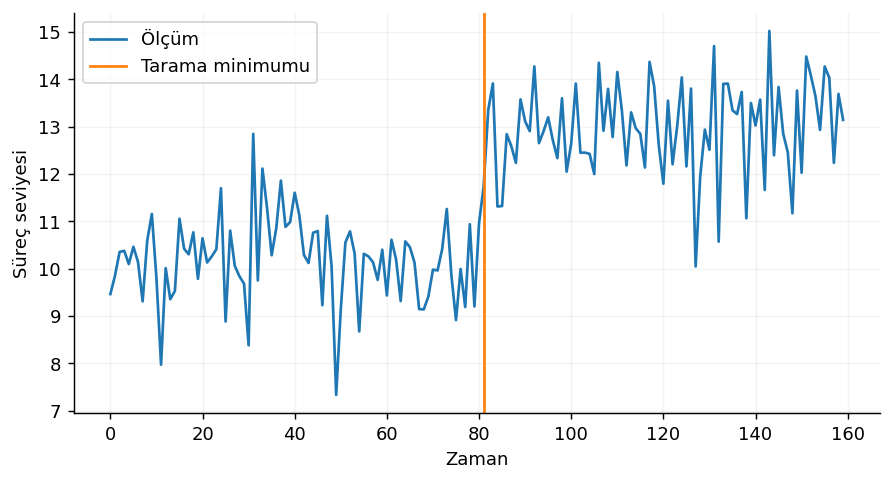

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=np.r_[rng.normal(10,1,80),rng.normal(13,1,80)];candidates=np.arange(20,len(x)-20);loss=np.array([((x[:k]-x[:k].mean())**2).sum()+((x[k:]-x[k:].mean())**2).sum() for k in candidates]);best=int(candidates[loss.argmin()]);print({'secilen_kirilma':best,'once':x[:best].mean(),'sonra':x[best:].mean()})
plt.plot(x,label='Ölçüm');plt.axvline(best,c='tab:orange',label='Tarama minimumu');plt.xlabel('Zaman');plt.ylabel('Süreç seviyesi');plt.legend()

## Durum uzayı ve Kalman filtresi

Gürültülü ölçümde gizli seviyeyi nasıl izlerim?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Ölçüm, gerçek simülasyon seviyesi ve filtre tahminini ayır.

**Yorum sınırı:** Yerel seviye Kalman modeli Q/R sabit kabul eder; geleceği kullanan smoother uygulanmaz.

**Alıştırma:** Q=.08 yerine .8 kullan; tepki hızı ile oynaklık dengesini açıkla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'olcum_RMSE': np.float64(1.0186924953419716), 'filtre_RMSE': np.float64(0.45911919785522864)}


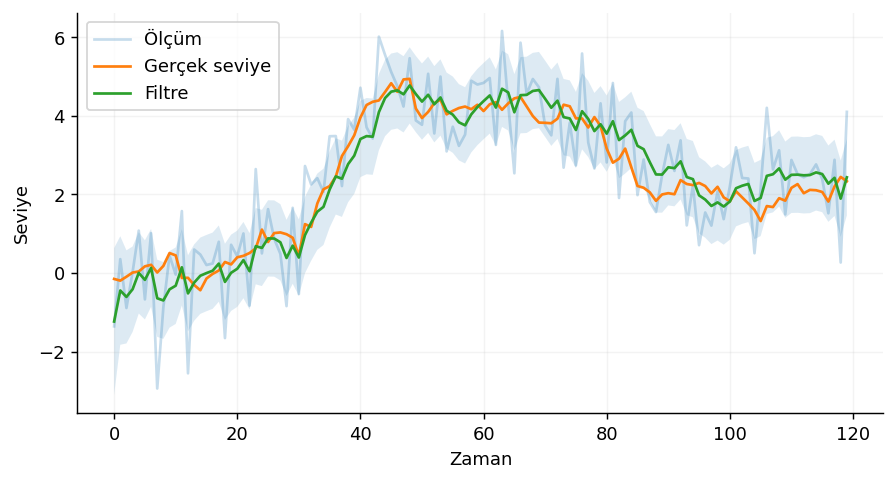

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

Q,R=.08,1.;true=np.cumsum(rng.normal(0,np.sqrt(Q),120));obs=true+rng.normal(0,np.sqrt(R),120);m,P=0.,10.;est=[];unc=[]
for y in obs:
 P+=Q;K=P/(P+R);m+=K*(y-m);P=(1-K)*P;est.append(m);unc.append(P)
est=np.array(est);sd=np.sqrt(unc);print({'olcum_RMSE':np.sqrt(np.mean((obs-true)**2)),'filtre_RMSE':np.sqrt(np.mean((est-true)**2))})
plt.plot(obs,alpha=.25,label='Ölçüm');plt.plot(true,label='Gerçek seviye');plt.plot(est,label='Filtre');plt.fill_between(range(len(est)),est-1.96*sd,est+1.96*sd,alpha=.15);plt.xlabel('Zaman');plt.ylabel('Seviye');plt.legend()

## Çoklu seriler ve hiyerarşik tahmin

Bağlı serileri ve toplamı tutarlı nasıl tahmin ederim?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** VAR tahminlerini aynı test döneminde son değer tabanıyla karşılaştır.

**Yorum sınırı:** VAR(1) ve bottom-up toplam örneği; genel hiyerarşi uzlaştırması veya nedensel yön çıkarımı değildir.

**Alıştırma:** Çapraz etkiyi .3’ten 0’a indir; taban modeline göre kazancı incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'VAR_MSE': 2.8534877404608547, 'son_deger_MSE': 3.0656484193778137, 'toplam_MSE': 7.6489254520351455}


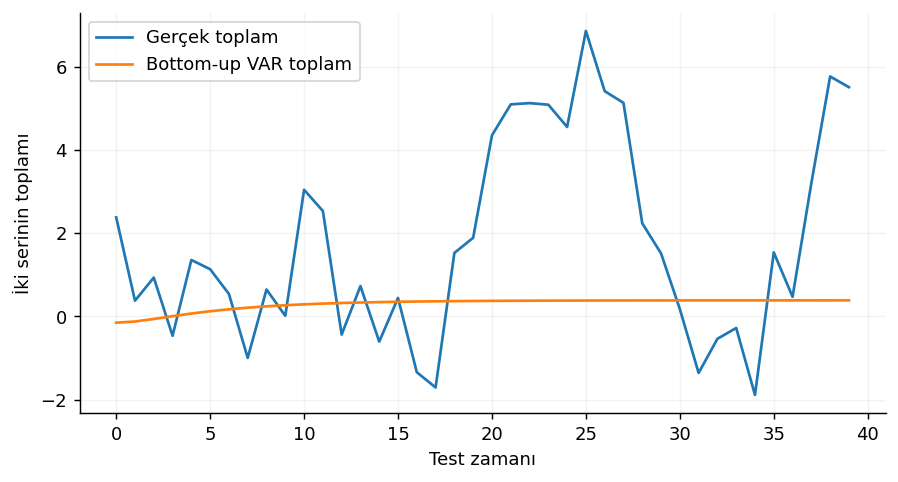

In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from statsmodels.tsa.api import VAR
x=np.zeros((220,2));A=np.array([[.65,.3],[.1,.55]])
for t in range(1,len(x)):x[t]=A@x[t-1]+rng.normal(size=2)
train,test=x[:180],x[180:];fit=VAR(train).fit(1);pred=fit.forecast(train[-1:],len(test));naive=np.repeat(train[-1:],len(test),axis=0);print({'VAR_MSE':mean_squared_error(test,pred),'son_deger_MSE':mean_squared_error(test,naive),'toplam_MSE':mean_squared_error(test.sum(axis=1),pred.sum(axis=1))})
plt.plot(test.sum(axis=1),label='Gerçek toplam');plt.plot(pred.sum(axis=1),label='Bottom-up VAR toplam');plt.xlabel('Test zamanı');plt.ylabel('İki serinin toplamı');plt.legend()